<a href="https://colab.research.google.com/github/aubriannaps/PCD_Assignment03/blob/main/PCD_Assignment03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Implementation of Segmentation and 4 Basic Morphological Methods for Digital Image Processing

# Segmentation by Thresholding
Performed by grayscaling original image, performing Gaussian blur on it, then observing the histogram values to obtain the optimal threshold level to segment the image, in which 0.6 is chosen as the optimal threshold level as it is the area between the grey and the pure white area. While values of 0.7-0.8 prove more effective in reducing noise, the value of 0.6 is chosen instead to observe the effects of the 4 morphological methods on the image, especially the small spots.



Mounted at /content/drive


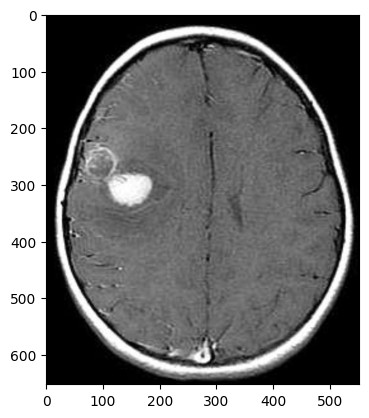

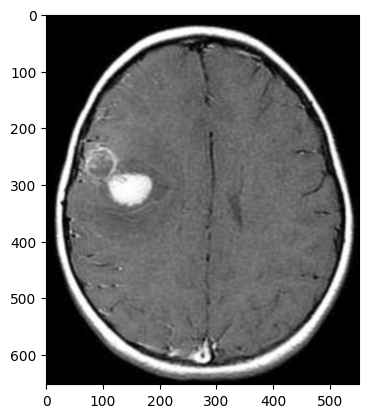

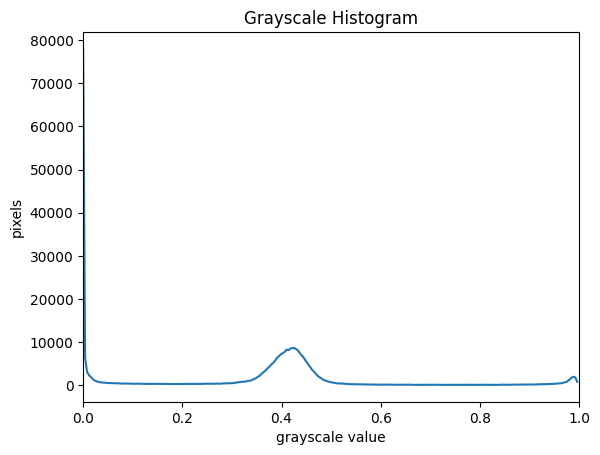

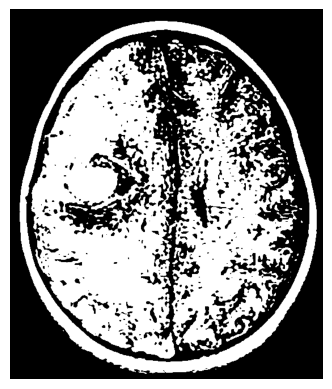

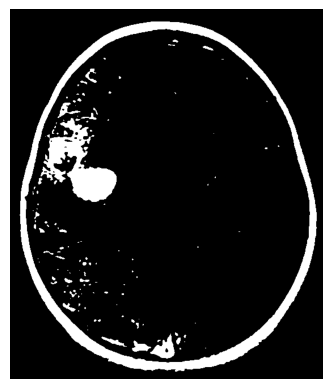

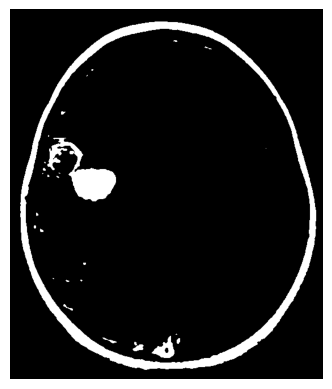

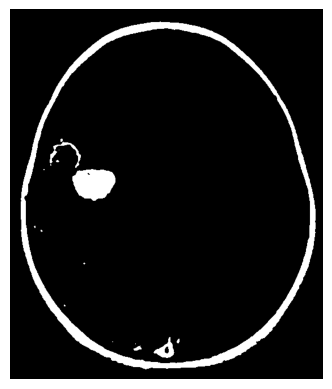

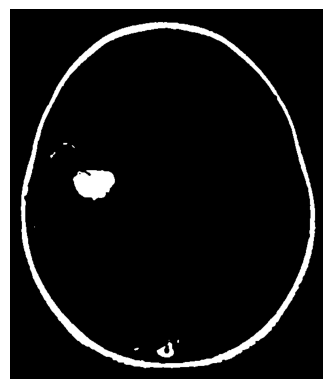

In [96]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy import ndimage

import skimage as ski

from google.colab import drive

drive.mount('/content/drive', force_remount=True)

image_path = '/content/drive/MyDrive/PencitraanDigital/tumor.png'

img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

plt.imshow(img, cmap='gray')
plt.axis('on')
plt.show()

blurred_shapes = ski.filters.gaussian(img, sigma=1.0)
histogram, bin_edges = np.histogram(blurred_shapes, bins=256, range=(0.0, 1.0))

plt.imshow(blurred_shapes, cmap='gray')
plt.show()

fig, ax = plt.subplots()
ax.plot(bin_edges[0:-1], histogram)
ax.set_title("Grayscale Histogram")
ax.set_xlabel("grayscale value")
ax.set_ylabel("pixels")
ax.set_xlim(0, 1.0)

t = 0.4
binary_mask = blurred_shapes > t

fig, ax = plt.subplots()
plt.axis('off')
ax.imshow(binary_mask, cmap="gray")

t = 0.5
binary_mask = blurred_shapes > t

fig, ax = plt.subplots()
plt.axis('off')
ax.imshow(binary_mask, cmap="gray")

t = 0.6
binary_mask = blurred_shapes > t

fig, ax = plt.subplots()
plt.axis('off')
ax.imshow(binary_mask, cmap="gray")

t = 0.7
binary_mask = blurred_shapes > t

fig, ax = plt.subplots()
plt.axis('off')
ax.imshow(binary_mask, cmap="gray")

t = 0.8
binary_mask = blurred_shapes > t

fig, ax = plt.subplots()
plt.axis('off')
ax.imshow(binary_mask, cmap="gray")


# Basic Morphological Methods
Note that both Dilation and Erosion use an 3x3 structuring element/kernel with all 1 in it, which is the default option for the operation that performs it.

# Dilation

Mounted at /content/drive


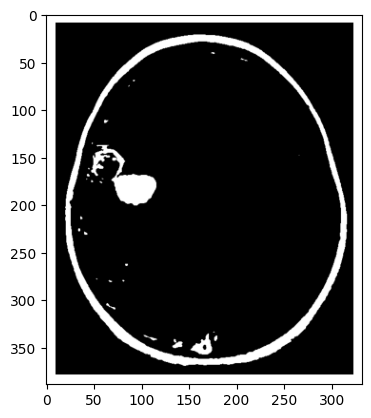

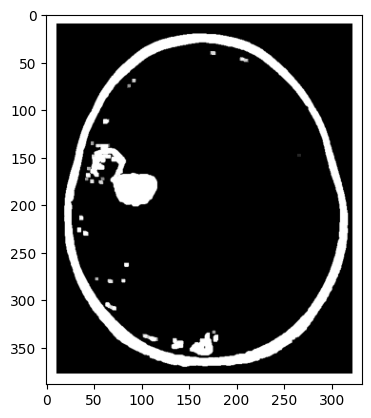

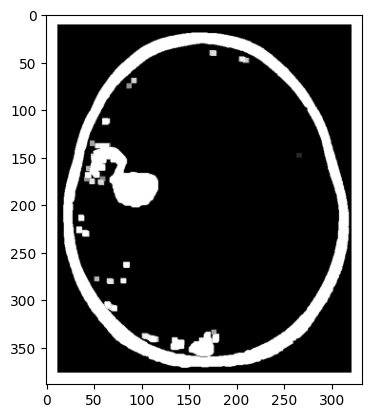

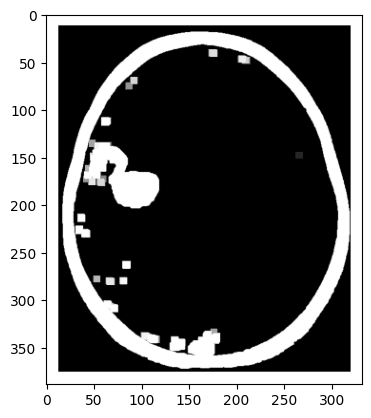

In [69]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy import ndimage

import skimage as ski

from google.colab import drive

drive.mount('/content/drive', force_remount=True)

image_path = '/content/drive/MyDrive/PencitraanDigital/segmented.png'

img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
plt.imshow(img, cmap='gray')
plt.axis('on')
plt.show()

erosion = cv2.dilate(img.copy(), None, iterations=1)
plt.imshow(erosion, cmap='gray')
plt.show()

erosionn = cv2.dilate(img.copy(), None, iterations=2)
plt.imshow(erosionn, cmap='gray')
plt.show()

erosionnn = cv2.dilate(img.copy(), None, iterations=3)
plt.imshow(erosionnn, cmap='gray')
plt.show()

Dilation expands the existing regions into bigger and bigger areas as more iterations pass. The borders of the images grow drastically as more iterations are performed; most notably, the outer circle touches the white border of the original image in the third and final iteration. It makes the area bigger the more iterations are performed.

# Erosion

Mounted at /content/drive


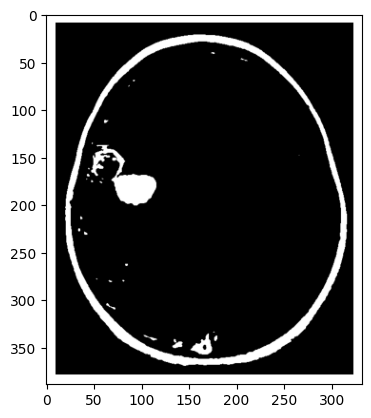

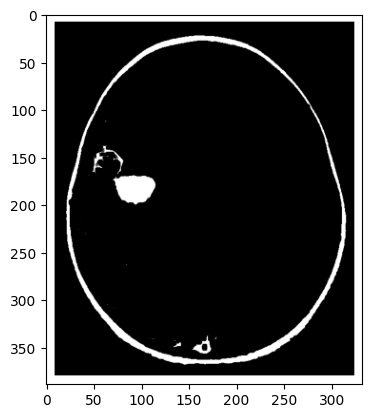

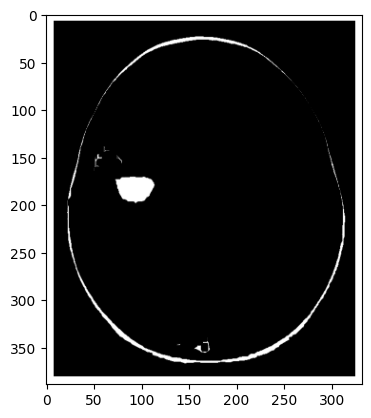

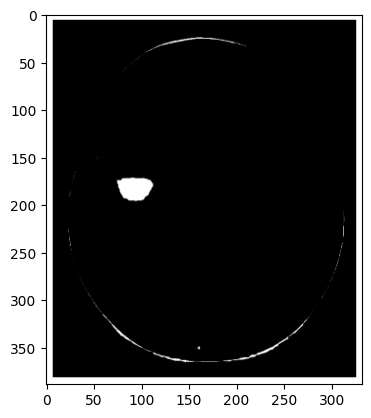

In [98]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy import ndimage

import skimage as ski

from google.colab import drive

drive.mount('/content/drive', force_remount=True)

image_path = '/content/drive/MyDrive/PencitraanDigital/segmented.png'

img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
plt.imshow(img, cmap='gray')
plt.axis('on')
plt.show()

erosion = cv2.erode(img.copy(), None, iterations=1)
plt.imshow(erosion, cmap='gray')
plt.show()

erosionn = cv2.erode(img.copy(), None, iterations=2)
plt.imshow(erosionn, cmap='gray')
plt.show()

erosionnn = cv2.erode(img.copy(), None, iterations=3)
plt.imshow(erosionnn, cmap='gray')
plt.show()

Erosion is used to erode an image's boundaries and make holes larger. The more iterations are performed, the smaller the white areas of an image will get.

# Opening


Mounted at /content/drive


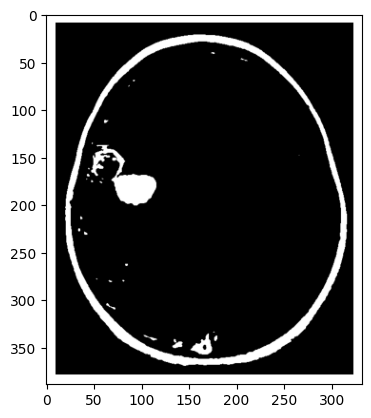

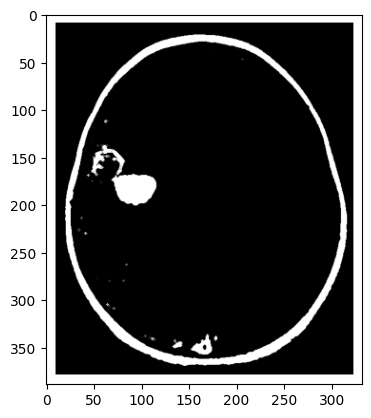

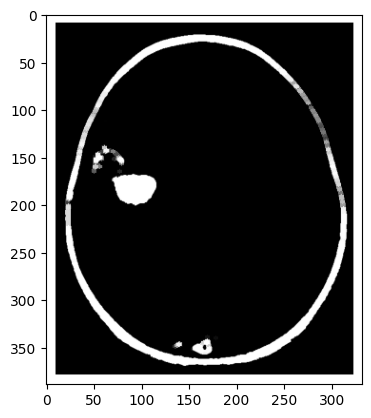

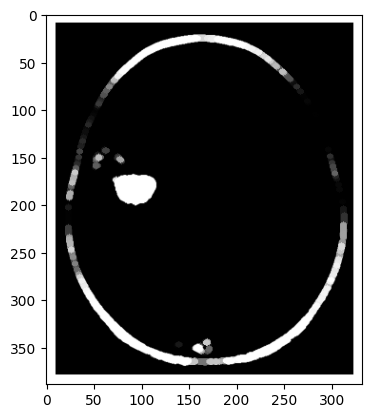

In [88]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy import ndimage

import skimage as ski

from google.colab import drive

drive.mount('/content/drive', force_remount=True)

image_path = '/content/drive/MyDrive/PencitraanDigital/segmented.png'

img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
plt.imshow(img, cmap='gray')
plt.axis('on')
plt.show()

kernelSize2 = (3, 3)
kernel2 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, kernelSize2)

erosion = cv2.erode(img.copy(), kernel2, iterations=1)
dilated = cv2.dilate(erosion, kernel2, iterations=1)
plt.imshow(dilated, cmap='gray')
plt.show()

kernelSize = (5, 5)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, kernelSize)

erosion = cv2.erode(img.copy(), kernel, iterations=1)
dilated = cv2.dilate(erosion, kernel, iterations=1)
plt.imshow(dilated, cmap='gray')
plt.show()

kernelSize3 = (7, 7)
kernel3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, kernelSize3)

erosion = cv2.erode(img.copy(), kernel3, iterations=1)
dilated = cv2.dilate(erosion, kernel3, iterations=1)
plt.imshow(dilated, cmap='gray')
plt.show()


Opening is essentially erosion and then dilation on the same image using the same kernel. In this case, an elliptical kernel was used with increasing sizes of 3x3, 5x5 and 7x7.

# Closing


Mounted at /content/drive


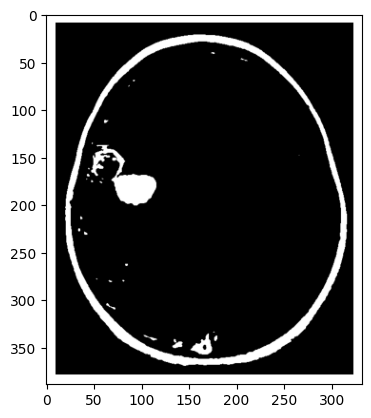

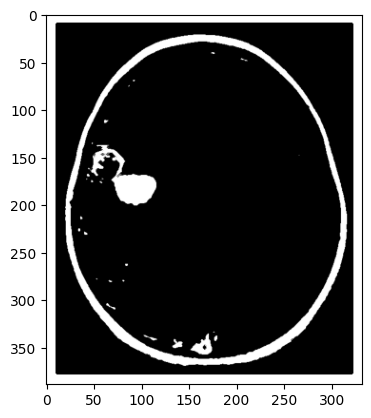

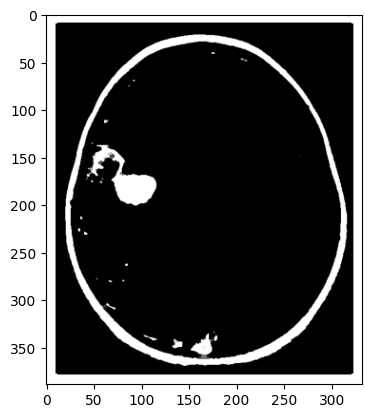

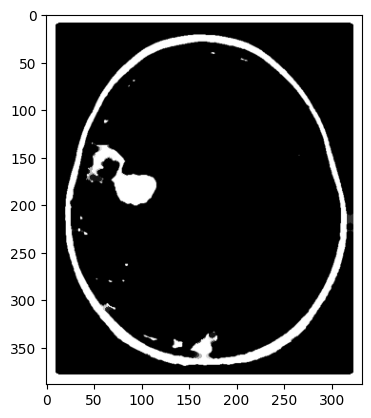

In [97]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy import ndimage

import skimage as ski

from google.colab import drive

drive.mount('/content/drive', force_remount=True)

image_path = '/content/drive/MyDrive/PencitraanDigital/segmented.png'

img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
plt.imshow(img, cmap='gray')
plt.axis('on')
plt.show()

kernelSize3 = (3, 3)
kernel3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, kernelSize3)
dilation = cv2.dilate(img.copy(), kernel3, iterations=1)
eroded = cv2.erode(dilation, kernel3, iterations=1)
plt.imshow(eroded, cmap='gray')
plt.show()

kernelSize = (5, 5)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, kernelSize)
dilation = cv2.dilate(img.copy(), kernel, iterations=1)
eroded = cv2.erode(dilation, kernel, iterations=1)
plt.imshow(eroded, cmap='gray')
plt.show()

kernelSize2 = (7, 7)
kernel2 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, kernelSize2)
dilation = cv2.dilate(img.copy(), kernel2, iterations=1)
eroded = cv2.erode(dilation, kernel2, iterations=1)
plt.imshow(eroded, cmap='gray')
plt.show()

Closing is dilation performed after erosion using the same kernel. In this case, an elliptical kernel was used with increasing sizes of 3x3, 5x5 and 7x7.